In [ ]:
# purpose: given a molecule of interest, protonate at a given pH and generate optimized 3D coordinates as input for docking, DFT, and more
# i usually use conda for environment control for any packages i use (conda install -c conda-forge rdkit)
# for the sake of this notebook though i just used pip to install rdkit
%pip install rdkit
%pip install dimorphite_dl

   ---------------------------------------- 0.0/25.9 MB ? eta -:--:--
   ---- ----------------------------------- 2.6/25.9 MB 14.7 MB/s eta 0:00:02
   --------- ------------------------------ 6.0/25.9 MB 15.5 MB/s eta 0:00:02
   -------------- ------------------------- 9.4/25.9 MB 16.1 MB/s eta 0:00:02
   ------------------- -------------------- 12.8/25.9 MB 16.1 MB/s eta 0:00:01
   ------------------------ --------------- 16.0/25.9 MB 16.2 MB/s eta 0:00:01
   ----------------------------- ---------- 18.9/25.9 MB 15.8 MB/s eta 0:00:01
   ---------------------------------- ----- 22.3/25.9 MB 15.9 MB/s eta 0:00:01
   ---------------------------------------  25.7/25.9 MB 16.0 MB/s eta 0:00:01
   ---------------------------------------- 25.9/25.9 MB 15.4 MB/s  0:00:01
   ---------------------------------------- 0.0/12.7 MB ? eta -:--:--
   ---------- ----------------------------- 3.4/12.7 MB 17.5 MB/s eta 0:00:01
   --------------------- ------------------ 6.8/12.7 MB 17.1 MB/s eta 0:00:01

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.



   ------------- -------------------------- 1/3 [loguru]
   -------------------------- ------------- 2/3 [dimorphite_dl]
   ---------------------------------------- 3/3 [dimorphite_dl]

Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [6]:
# get smiles from RCSB PDB or even pdbqt output file after docking (note: will have no hydrogens)
# use dimorphite_dl to protonate your molecule of interest at a given pH
from dimorphite_dl import protonate_smiles
smi = "NC(=O)c1ccc[n+](c1)[CH]2O[CH](CO[P]([O-])(=O)O[P](O)(=O)OC[CH]3O[CH]([CH](O[P](O)(O)=O)[CH]3O)n4cnc5c(N)ncnc45)[CH](O)[CH]2O"
protonated_smiles = protonate_smiles(smi, ph_min=7.4, ph_max=7.4)
print(protonated_smiles)

['NC(=O)c1ccc[n+](C2OC(COP(=O)([O-])OP(=O)([O-])OCC3OC(n4cnc5c(N)ncnc54)C(OP(=O)([O-])[O-])C3O)C(O)C2O)c1', 'NC(=O)c1ccc[n+](C2OC(COP(=O)([O-])OP(=O)([O-])OCC3OC(n4cnc5c(N)ncnc54)C(OP(=O)([O-])O)C3O)C(O)C2O)c1']


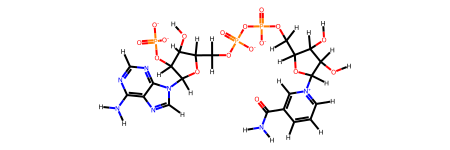

In [ ]:
from rdkit import Chem
from rdkit.Chem import AllChem

#load the smiles and add nonpolar hydrogens
#load in the SMILES string output from dimorphite_dl
smi = "NC(=O)c1ccc[n+](C2OC(COP(=O)([O-])OP(=O)([O-])OCC3OC(n4cnc5c(N)ncnc54)C(OP(=O)([O-])[O-])C3O)C(O)C2O)c1"
molec = Chem.AddHs(Chem.MolFromSmiles(smi))

#show image of molecule
molec

embed status: 0


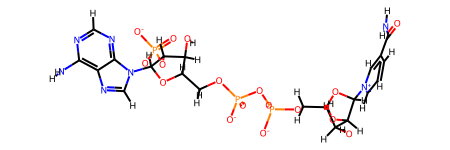

In [8]:
#generate a conformer using the most recent stable version (v3) couldn't get v4 to work
params = AllChem.ETKDGv3()
params.randomSeed = 13
status = AllChem.EmbedMolecule(molec, params)

#conformer generation failed if it returns -1, succeeded if returns 0
print("embed status:", status)
#show updated molecular geometry
molec

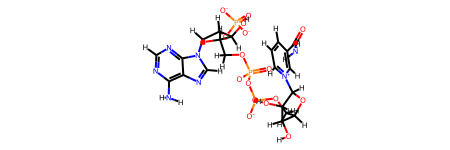

In [9]:
#optimize geometry with 5000 iterations
AllChem.MMFFOptimizeMolecule(molec, maxIters=5000)

#show optimized geometry
molec

In [10]:
#export as sdf file
Chem.MolToMolFile(molec, "NADP.sdf")
#print coordinates of top 10 atoms
coords = molec.GetConformer().GetPositions()
symbols = [atom.GetSymbol() for atom in molec.GetAtoms()]

for sym, (x, y, z) in list(zip(symbols,coords))[:10]:
    print(f'{sym:2s} {x:9.4f} {y:9.4f} {z:9.4f}')

N     3.9497    1.4096   -3.1524
C     3.9501    2.0800   -1.9639
O     4.5302    3.1519   -1.8330
C     3.2913    1.4126   -0.8234
C     2.5858    2.1475    0.1125
C     2.0670    1.4961    1.2237
C     2.3173    0.1449    1.4203
N     3.0833   -0.5522    0.5428
C     3.7232   -1.8273    0.9680
O     4.5376   -2.4359   -0.0584
